In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.preprocessing import (
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    make_scorer
)

In [2]:
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

dataset_path = (
    project_root
    / "data"
    / "raw"
    / "manufacturing_6G_dataset.csv"
)

figures_dir = project_root / "figures"
figures_dir.mkdir(exist_ok=True)

df = pd.read_csv(dataset_path)

df["Timestamp"] = pd.to_datetime(
    df["Timestamp"]
)

print("Dataset shape:", df.shape)

Dataset shape: (100000, 13)


In [3]:
X = df.drop(
    columns=[
        "Efficiency_Status",
        "Timestamp",
        "Machine_ID"
    ]
)

y = df["Efficiency_Status"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

X shape: (100000, 10)
y shape: (100000,)

Features:
['Operation_Mode', 'Temperature_C', 'Vibration_Hz', 'Power_Consumption_kW', 'Network_Latency_ms', 'Packet_Loss_%', 'Quality_Control_Defect_Rate_%', 'Production_Speed_units_per_hr', 'Predictive_Maintenance_Score', 'Error_Rate_%']


In [4]:
X_development, X_test, y_development, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

X_train, X_validation, y_train, y_validation = (
    train_test_split(
        X_development,
        y_development,
        test_size=0.20,
        random_state=42,
        stratify=y_development
    )
)

print("Training:", X_train.shape)
print("Validation:", X_validation.shape)
print("Final Test:", X_test.shape)

Training: (64000, 10)
Validation: (16000, 10)
Final Test: (20000, 10)


In [5]:
numerical_features = [
    "Temperature_C",
    "Vibration_Hz",
    "Power_Consumption_kW",
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Quality_Control_Defect_Rate_%",
    "Production_Speed_units_per_hr",
    "Predictive_Maintenance_Score",
    "Error_Rate_%"
]

categorical_features = [
    "Operation_Mode"
]

class_order = [
    "Low",
    "Medium",
    "High"
]

In [6]:
tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            "passthrough",
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

tree_preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``

In [7]:
forest_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            tree_preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [8]:
forest_pipeline.fit(
    X_train,
    y_train
)

print(
    "Random Forest trained successfully."
)

Random Forest trained successfully.


In [9]:
preprocessor = (
    forest_pipeline
    .named_steps["preprocessing"]
)

feature_names = (
    preprocessor
    .get_feature_names_out()
)

print(feature_names)

['numerical__Temperature_C' 'numerical__Vibration_Hz'
 'numerical__Power_Consumption_kW' 'numerical__Network_Latency_ms'
 'numerical__Packet_Loss_%' 'numerical__Quality_Control_Defect_Rate_%'
 'numerical__Production_Speed_units_per_hr'
 'numerical__Predictive_Maintenance_Score' 'numerical__Error_Rate_%'
 'categorical__Operation_Mode_Active' 'categorical__Operation_Mode_Idle'
 'categorical__Operation_Mode_Maintenance']


In [10]:
forest_model = (
    forest_pipeline
    .named_steps["model"]
)

feature_importances = (
    forest_model
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

importance_df = (
    importance_df
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

importance_df

,Feature,Importance
0,numerical__Error_Rate_%,0.664653
1,numerical__Production_Speed_units_per_hr,0.317092
2,numerical__Temperature_C,0.002775
3,numerical__Predictive_Maintenance_Score,0.002551
4,numerical__Network_Latency_ms,0.002491
5,numerical__Power_Consumption_kW,0.002484
6,numerical__Vibration_Hz,0.002471
7,numerical__Quality_Control_Defect_Rate_%,0.002429
8,numerical__Packet_Loss_%,0.002423
9,categorical__Operation_Mode_Active,0.000254


In [11]:
importance_df["Feature"] = (
    importance_df["Feature"]
    .str.replace(
        "numerical__",
        "",
        regex=False
    )
    .str.replace(
        "categorical__",
        "",
        regex=False
    )
)

importance_df

,Feature,Importance
0,Error_Rate_%,0.664653
1,Production_Speed_units_per_hr,0.317092
2,Temperature_C,0.002775
3,Predictive_Maintenance_Score,0.002551
4,Network_Latency_ms,0.002491
5,Power_Consumption_kW,0.002484
6,Vibration_Hz,0.002471
7,Quality_Control_Defect_Rate_%,0.002429
8,Packet_Loss_%,0.002423
9,Operation_Mode_Active,0.000254


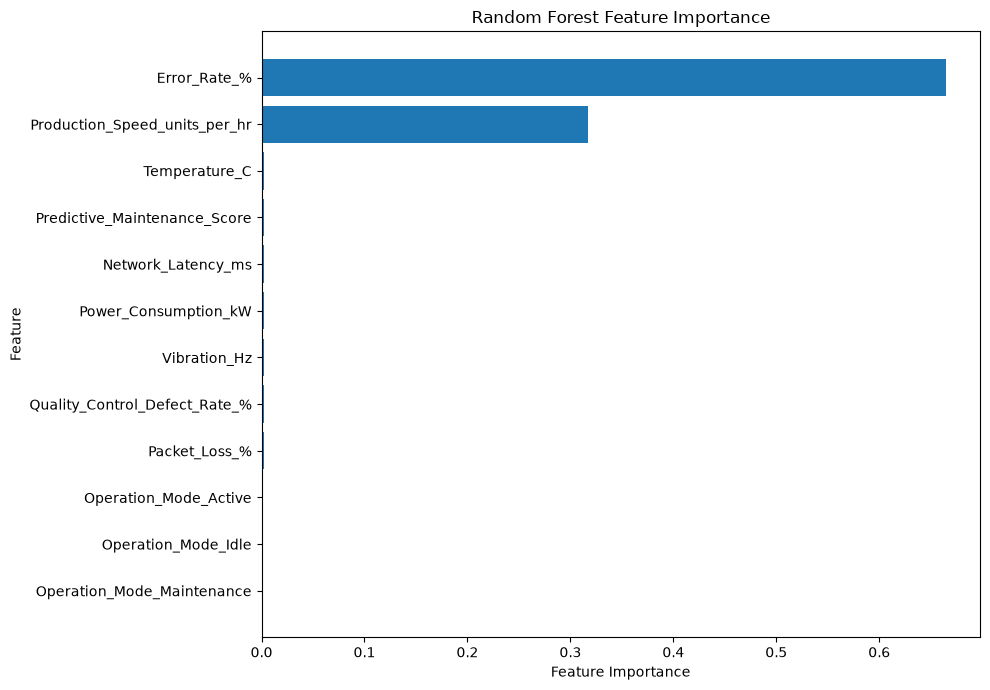

In [12]:
plot_importance = (
    importance_df
    .sort_values(
        by="Importance",
        ascending=True
    )
)

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    plot_importance["Feature"],
    plot_importance["Importance"]
)

plt.title(
    "Random Forest Feature Importance"
)

plt.xlabel(
    "Feature Importance"
)

plt.ylabel(
    "Feature"
)

plt.tight_layout()

plt.savefig(
    figures_dir
    / "random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
dominant_features = [
    "Production_Speed_units_per_hr",
    "Error_Rate_%"
]

dominant_importance = (
    importance_df[
        importance_df["Feature"]
        .isin(dominant_features)
    ]["Importance"]
    .sum()
)

print(
    "Combined importance of Production Speed "
    "and Error Rate:",
    round(dominant_importance, 4)
)

print(
    "Percentage:",
    round(
        dominant_importance * 100,
        2
    ),
    "%"
)

Combined importance of Production Speed and Error Rate: 0.9817
Percentage: 98.17 %


In [14]:
X_all = X.copy()

print(
    "Experiment A features:",
    X_all.columns.tolist()
)

print(
    "Number of features:",
    X_all.shape[1]
)

Experiment A features: ['Operation_Mode', 'Temperature_C', 'Vibration_Hz', 'Power_Consumption_kW', 'Network_Latency_ms', 'Packet_Loss_%', 'Quality_Control_Defect_Rate_%', 'Production_Speed_units_per_hr', 'Predictive_Maintenance_Score', 'Error_Rate_%']
Number of features: 10


In [16]:
features_to_remove = [
    "Production_Speed_units_per_hr",
    "Error_Rate_%"
]

X_reduced = X.drop(
    columns=features_to_remove
)

print(
    "Experiment B features:"
)

print(
    X_reduced.columns.tolist()
)

print(
    "\nNumber of features:",
    X_reduced.shape[1]
)

Experiment B features:
['Operation_Mode', 'Temperature_C', 'Vibration_Hz', 'Power_Consumption_kW', 'Network_Latency_ms', 'Packet_Loss_%', 'Quality_Control_Defect_Rate_%', 'Predictive_Maintenance_Score']

Number of features: 8


In [17]:
X_reduced_development = (
    X_reduced.loc[
        X_development.index
    ]
)

X_reduced_train = (
    X_reduced.loc[
        X_train.index
    ]
)

X_reduced_validation = (
    X_reduced.loc[
        X_validation.index
    ]
)

X_reduced_test = (
    X_reduced.loc[
        X_test.index
    ]
)

print(
    "Reduced training:",
    X_reduced_train.shape
)

print(
    "Reduced validation:",
    X_reduced_validation.shape
)

print(
    "Reduced final test:",
    X_reduced_test.shape
)

Reduced training: (64000, 8)
Reduced validation: (16000, 8)
Reduced final test: (20000, 8)


In [18]:
reduced_numerical_features = [
    feature
    for feature in numerical_features
    if feature
    not in features_to_remove
]

print(
    reduced_numerical_features
)

['Temperature_C', 'Vibration_Hz', 'Power_Consumption_kW', 'Network_Latency_ms', 'Packet_Loss_%', 'Quality_Control_Defect_Rate_%', 'Predictive_Maintenance_Score']


In [19]:
reduced_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            "passthrough",
            reduced_numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

In [20]:
reduced_forest_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            reduced_preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [21]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [22]:
scoring = {
    "accuracy": "accuracy",

    "macro_precision": make_scorer(
        precision_score,
        average="macro",
        zero_division=0
    ),

    "macro_recall": make_scorer(
        recall_score,
        average="macro",
        zero_division=0
    ),

    "macro_f1": make_scorer(
        f1_score,
        average="macro",
        zero_division=0
    )
}

In [23]:
all_feature_scores = cross_validate(
    forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

all_feature_results = {
    "Experiment":
        "All Features",

    "Accuracy":
        all_feature_scores[
            "test_accuracy"
        ].mean(),

    "Macro Precision":
        all_feature_scores[
            "test_macro_precision"
        ].mean(),

    "Macro Recall":
        all_feature_scores[
            "test_macro_recall"
        ].mean(),

    "Macro F1":
        all_feature_scores[
            "test_macro_f1"
        ].mean(),

    "Macro F1 Std":
        all_feature_scores[
            "test_macro_f1"
        ].std()
}

all_feature_results

{'Experiment': 'All Features',
 'Accuracy': np.float64(0.9999375012206535),
 'Macro Precision': np.float64(0.9999119478270924),
 'Macro Recall': np.float64(0.9994495671435395),
 'Macro F1': np.float64(0.9996801232585616),
 'Macro F1 Std': np.float64(0.0004169944902206847)}

In [24]:
reduced_feature_scores = cross_validate(
    reduced_forest_pipeline,
    X_reduced_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

reduced_feature_results = {
    "Experiment":
        "Without Production Speed and Error Rate",

    "Accuracy":
        reduced_feature_scores[
            "test_accuracy"
        ].mean(),

    "Macro Precision":
        reduced_feature_scores[
            "test_macro_precision"
        ].mean(),

    "Macro Recall":
        reduced_feature_scores[
            "test_macro_recall"
        ].mean(),

    "Macro F1":
        reduced_feature_scores[
            "test_macro_f1"
        ].mean(),

    "Macro F1 Std":
        reduced_feature_scores[
            "test_macro_f1"
        ].std()
}

reduced_feature_results

{'Experiment': 'Without Production Speed and Error Rate',
 'Accuracy': np.float64(0.7778125013563325),
 'Macro Precision': np.float64(0.3034632519394744),
 'Macro Recall': np.float64(0.3332891146913957),
 'Macro F1': np.float64(0.2920498041818609),
 'Macro F1 Std': np.float64(0.00034170385891129826)}

In [25]:
ablation_results = pd.DataFrame([
    all_feature_results,
    reduced_feature_results
])

ablation_results.round(4)

,Experiment,Accuracy,Macro Precision,Macro Recall,Macro F1,Macro F1 Std
0,All Features,0.9999,0.9999,0.9994,0.9997,0.0004
1,Without Production Speed and Error Rate,0.7778,0.3035,0.3333,0.2920,0.0003


In [26]:
comparison_results = pd.DataFrame([
    {
        "Experiment":
            "Majority Baseline",

        "Accuracy":
            0.7783,

        "Macro F1":
            0.2918
    },
    {
        "Experiment":
            "Random Forest All Features",

        "Accuracy":
            all_feature_results[
                "Accuracy"
            ],

        "Macro F1":
            all_feature_results[
                "Macro F1"
            ]
    },
    {
        "Experiment":
            "Random Forest Without Dominant Features",

        "Accuracy":
            reduced_feature_results[
                "Accuracy"
            ],

        "Macro F1":
            reduced_feature_results[
                "Macro F1"
            ]
    }
])

comparison_results.round(4)

,Experiment,Accuracy,Macro F1
0,Majority Baseline,0.7783,0.2918
1,Random Forest All Features,0.9999,0.9997
2,Random Forest Without Dominant Features,0.7778,0.2920


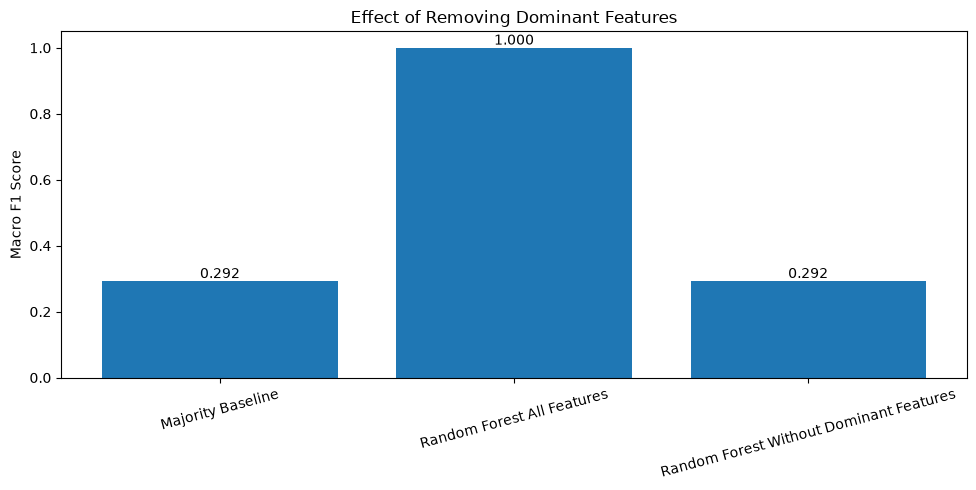

In [27]:
plt.figure(
    figsize=(10, 5)
)

bars = plt.bar(
    comparison_results[
        "Experiment"
    ],
    comparison_results[
        "Macro F1"
    ]
)

plt.title(
    "Effect of Removing Dominant Features"
)

plt.ylabel(
    "Macro F1 Score"
)

plt.ylim(
    0,
    1.05
)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        height,
        f"{height:.3f}",
        ha="center",
        va="bottom"
    )

plt.xticks(
    rotation=15
)

plt.tight_layout()

plt.savefig(
    figures_dir
    / "feature_ablation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
reduced_cv_predictions = (
    cross_val_predict(
        reduced_forest_pipeline,
        X_reduced_train,
        y_train,
        cv=cv,
        n_jobs=-1
    )
)

In [29]:
print(
    classification_report(
        y_train,
        reduced_cv_predictions,
        labels=class_order,
        zero_division=0,
        digits=4
    )
)

              precision    recall  f1-score   support

         Low     0.7782    0.9993    0.8750     49808
      Medium     0.1628    0.0006    0.0011     12281
        High     0.0000    0.0000    0.0000      1911

    accuracy                         0.7778     64000
   macro avg     0.3137    0.3333    0.2921     64000
weighted avg     0.6369    0.7778    0.6812     64000



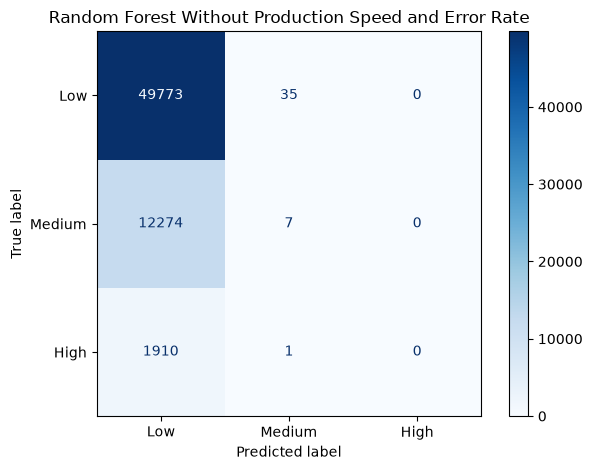

In [30]:
ConfusionMatrixDisplay.from_predictions(
    y_train,
    reduced_cv_predictions,
    labels=class_order,
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Random Forest Without Production Speed and Error Rate"
)

plt.tight_layout()

plt.savefig(
    figures_dir
    / "reduced_features_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
accuracy_drop = (
    all_feature_results["Accuracy"]
    -
    reduced_feature_results["Accuracy"]
)

macro_f1_drop = (
    all_feature_results["Macro F1"]
    -
    reduced_feature_results["Macro F1"]
)

print(
    "Accuracy drop:",
    round(
        accuracy_drop,
        4
    )
)

print(
    "Macro F1 drop:",
    round(
        macro_f1_drop,
        4
    )
)

Accuracy drop: 0.2221
Macro F1 drop: 0.7076


In [32]:
tree_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            tree_preprocessor
        ),
        (
            "model",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)

In [33]:
reduced_tree_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            reduced_preprocessor
        ),
        (
            "model",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)

In [34]:
tree_all_scores = cross_validate(
    tree_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

tree_reduced_scores = cross_validate(
    reduced_tree_pipeline,
    X_reduced_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

tree_ablation = pd.DataFrame([
    {
        "Experiment":
            "Decision Tree All Features",

        "Accuracy":
            tree_all_scores[
                "test_accuracy"
            ].mean(),

        "Macro F1":
            tree_all_scores[
                "test_macro_f1"
            ].mean()
    },
    {
        "Experiment":
            "Decision Tree Without Dominant Features",

        "Accuracy":
            tree_reduced_scores[
                "test_accuracy"
            ].mean(),

        "Macro F1":
            tree_reduced_scores[
                "test_macro_f1"
            ].mean()
    }
])

tree_ablation.round(4)

,Experiment,Accuracy,Macro F1
0,Decision Tree All Features,0.9999,0.9998
1,Decision Tree Without Dominant Features,0.6264,0.3328


# Feature Importance and Ablation Analysis

## Objective

The purpose of notebook 5 was to investigate why the tree based classification models achieved almost perfect performance.

Previous exploratory analysis identified two features with particularly strong relationships to the target:

`Production_Speed_units_per_hr`

`Error_Rate_%`

Random Forest feature importance and controlled feature ablation experiments were performed to investigate the contribution of these variables.

## Random Forest Feature Importance

The fitted Random Forest assigned approximately:

`66.47%` importance to `Error_Rate_%`

`31.71%` importance to `Production_Speed_units_per_hr`

Together, these two variables accounted for approximately `98.17%` of the total impurity based feature importance.

All remaining numerical and categorical features individually received very small importance values.

These results are consistent with the exploratory analysis performed during notebook 1 and 2.

Feature importance should not be interpreted as evidence of causation. It describes how strongly the fitted Random Forest relied on particular features when making its classification decisions.

## Random Forest Ablation Experiment

Two Random Forest experiments were compared using the same three fold stratified cross validation strategy.

### Experiment A: All Features

Using all candidate features, the Random Forest achieved approximately:

`Accuracy = 0.9999`

`Macro Precision = 0.9999`

`Macro Recall = 0.9994`

`Macro F1 = 0.9997`

### Experiment B: Without Production Speed and Error Rate

After removing `Production_Speed_units_per_hr` and `Error_Rate_%`, performance decreased to approximately:

`Accuracy = 0.7778`

`Macro Precision = 0.3035`

`Macro Recall = 0.3333`

`Macro F1 = 0.2920`

The removal of the two dominant features therefore caused an accuracy decrease of approximately `0.2221` and a Macro F1 decrease of approximately `0.7076`.

## Comparison With the Majority Baseline

The majority class baseline from the previous experiment achieved approximately:

`Accuracy = 0.7783`

`Macro F1 = 0.2918`

The Random Forest without Production Speed and Error Rate achieved almost identical performance:

`Accuracy = 0.7778`

`Macro F1 = 0.2920`

This indicates that after removing the two dominant features, the remaining variables provide very little additional predictive information for reconstructing the provided Efficiency Status labels.

## Reduced Model Error Analysis

The cross validated confusion matrix showed that the reduced Random Forest predicted almost every observation as `Low`.

Among the 12,281 actual Medium observations, only 7 were correctly classified as Medium.

Among the 1,911 actual High observations, none were correctly classified as High.

As a result, the High class had zero precision, zero recall, and zero F1 score.

This demonstrates why overall accuracy alone is misleading for this dataset. Although the reduced model retained approximately 77.8% accuracy, it almost completely failed to identify the minority Medium and High classes.

## Decision Tree Ablation

The same ablation experiment was also performed using the Decision Tree classifier.

With all features, the Decision Tree achieved approximately:

`Accuracy = 0.9999`

`Macro F1 = 0.9998`

After removing Production Speed and Error Rate, performance decreased to approximately:

`Accuracy = 0.6264`

`Macro F1 = 0.3328`

The substantial deterioration in both Random Forest and Decision Tree performance shows that the result is not limited to one particular classifier.

## Interpretation

The exploratory analysis, manual threshold investigation, feature importance analysis, and feature ablation experiments all support the same conclusion.

Production Speed and Error Rate contain the dominant predictive information required to reconstruct the provided `Efficiency_Status` labels.

The near perfect performance of Decision Tree and Random Forest models can therefore be explained by the simple threshold based structure of the target variable.

This does not demonstrate that Production Speed and Error Rate alone determine manufacturing efficiency in real industrial environments.

Instead, it describes the predictive structure present in this particular dataset.

## Final Test Set

The reserved final test dataset remained untouched throughout the feature importance and ablation experiments.

It will only be used during the final evaluation after model selection has been completed.

## Conclusion

Removing Production Speed and Error Rate reduced Random Forest Macro F1 from approximately `0.9997` to `0.2920`, which is almost identical to the majority class baseline.

The two variables also accounted for approximately `98.17%` of the Random Forest feature importance.

Together with the Decision Tree ablation result, these findings provide strong evidence that the extremely high classification performance observed in this project primarily results from the target structure associated with Production Speed and Error Rate rather than complex relationships involving all available manufacturing variables.